# Study 1: from coded sources to the results

This notebook rebuilds the data, regression results, tables and figures. Please keep it beside the Python files and the `data` folder. Install `requirements.txt` first, then choose **Run all**. No account, API key or original computer path is needed.

An observation is an independent experiment or separately recruited sample. Conditions and repeated tasks within the same experiment are combined before fitting a model. The source files retain their agreement counts, payoff links, coding decisions and evidence.


## 1. Rebuild everything

The command below checks all payoff calculations, joins the coded outcomes and controls, and constructs the main and stricter datasets. It then fits the five models, the negotiation-count weighted comparison, and the planned checks. Resampling uses 5,000 complete-observation draws with recorded seeds. The final step produces the paper's tables and figures. The run may take a few minutes.

The coding rules and source locations are described in `README.md` and in `DATASET.md`. This code checks and processes the released coding; it does not replace reading the papers or deciding which teaching materials they used.


The same run also saves the separate Appendix A tests of the original registration, using the corrected combined-payoff data. Those original tests use their own hypothesis labels and the full original confirmation rules; they are separate from the current experiment-level tests.


In [1]:
from pathlib import Path
from run import reproduce

output = reproduce()


main: 141 observations


strict: 126 observations


aggregate_main: 103 observations


aggregate_strict: 87 observations


The replication files are in outputs/.


## 2. Check what went into the analysis

The main dataset retains all included observations. The stricter check removes unresolved assumptions that can change an outcome or predictor. One experiment contributes only the conditions whose separate outcomes and reservation values can be recovered. The eligibility file explains every decision. All 103 included payoff records must have a successful metric replay.


In [2]:
import json
import pandas as pd
from IPython.display import display, Markdown, Image

display(pd.read_csv(output / "observation_eligibility.csv"))
checks = pd.read_csv(output / "payoff_metric_checks.csv")
display(checks.groupby(["input_type", "recomputed_from_included_input"]).size().rename("Payoff records").reset_index())
assert checks.recomputed_from_included_input.all()
print(json.loads((output / "analysis_summary.json").read_text()))


,observation_id,paper_citation,study_label,negotiation_exercise,strict_included,strict_coverage,main_component_count,strict_component_count,main_negotiations,strict_negotiations,excluded_component_ids,reason
0,SRU0286,"Arunachalam, V., Dilla, W., Shelley, M., & Cha...",Experiment 1,Market Alternatives Transfer Pricing,Y,Recoverable subset of conditions,4,3,338.0,62.0,SLO0429::market_alternatives_remaining_13_pooled,"The combined agreement count is exact, but the..."
1,PET2025_2b,"Petrowsky, H. M., Boecker, L., Escher, Y. A., ...",Study 2b,Sale of a Café,N,No conditions meet the stricter evidence rule,4,0,1069.0,NaN,PET2025_2b_1::sale_cafe_buyer_cap_1550 | PET20...,The programmed-counterpart acceptance cap is r...
2,SRU0324,"Dannals, J. E., Zlatev, J. J., Halevy, N., & N...",Study 1,New Recruit,Y,All eligible conditions,3,3,1276.0,1276.0,NaN,The source identifies the observed outcome and...
3,SRU0334,"Kray, L. J., Reb, J., Galinsky, A. D., & Thomp...",Study 1,New Recruit,Y,All eligible conditions,1,1,47.0,47.0,NaN,The source identifies the observed outcome and...
4,SRU0343,"Kung, F. Y. H., & Chao, M. M. (2019). The impa...",Study 1,Sweet Shops,Y,All eligible conditions,1,1,105.0,105.0,NaN,The source identifies the observed outcome and...
...,...,...,...,...,...,...,...,...,...,...,...,...
136,SRU0128,"O'Connor, K. M., & Arnold, J. A. (2001). Distr...",Study 1,Confetti,Y,All eligible conditions,1,1,58.0,58.0,NaN,The original studies identify Confetti with th...
137,SRU0129,"O'Connor, K. M., & Arnold, J. A. (2001). Distr...",Study 2,Confetti,Y,All eligible conditions,1,1,83.0,83.0,NaN,The original studies identify Confetti with th...
138,SRU0130,"O'Connor, K. M., & Arnold, J. A. (2001). Distr...",Study 3,Confetti,Y,All eligible conditions,1,1,91.0,91.0,NaN,The original studies identify Confetti with th...
139,OC2005_STUDY1,"O'Connor, K. M., Arnold, J. A., & Burris, E. R...",Study 1,Confetti | Honors Class,Y,All eligible conditions,2,2,262.0,262.0,NaN,The source identifies the observed outcome and...


,input_type,recomputed_from_included_input,Payoff records
0,Option-level payoff catalogue,True,85
1,Reconstructed programmed acceptance rule,True,4
2,Sampled starts with complete two-party path ch...,True,1
3,Source payoff function with recorded grid and ...,True,8
4,Source-based acceptability proof,True,5


{'bootstrap_draws': 5000, 'base_seed': 20261111, 'samples': {'main': {'n': 141, 'weighted_n': 140}, 'strict': {'n': 126, 'weighted_n': 125}, 'aggregate_main': {'n': 103, 'weighted_n': None}, 'aggregate_strict': {'n': 87, 'weighted_n': None}}}


## 3. Read the results

Table 1 gives descriptive statistics and correlations. Table 2 reports the five main regression models. Table 3 reports the additional checks. Tables S1–S3 give the complete regressions for the stricter and combined-payoff comparisons.

The primary H1 test asks whether search complexity has a negative coefficient with a two-sided p value below .05 in Model 3. The primary H2 comparison asks whether search complexity and controls (Model 2) explain more variance than bargaining-zone size and the same controls (Model 5).

A full-sample result alone is insufficient for confirmation. H1 also requires its 95% interval from 5,000 individual-observation resamples to stay below zero, and its coefficient to stay negative with p < .05 after removing each observation in turn. H2 also requires a resampling interval for the R-squared difference entirely above zero, and a positive difference after every single-observation omission. Each requirement is reported separately in `hypothesis_tests.csv`; `full_confirmation_met` is true only if all pass.

These confirmation checks matter because the practical stopping rule does not fix the final analysis sample size: it depends on the archival evidence we can recover. An interval including zero or a failed omission would mean that the full confirmation criterion is not met, even if the primary result passes.

The weighted check gives observations with more negotiation attempts more weight; it excludes observations without a usable count. The stricter check removes unresolved coding assumptions. The combined-payoff comparison gives one row to each coded payoff record and fits the five models. The separate original-main appendix below applies the old registration's original hypothesis labels and confirmation rules to those combined-payoff data.


In [3]:
display(Markdown((output / "tables.md").read_text(encoding="utf-8")))
display(pd.read_csv(output / "hypothesis_tests.csv"))
display(pd.read_csv(output / "bootstrap_intervals.csv"))
display(pd.read_csv(output / "leave_one_out.csv").groupby(["dataset", "weighted"]).agg(
    checks=("omitted_observation", "size"),
    smallest_coefficient=("search_complexity_b", "min"),
    largest_coefficient=("search_complexity_b", "max"),
    negative_and_significant=("negative_and_significant", "sum")))


## Table 1. Descriptive statistics and correlations

| Variable | Mean | SD | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1. Agreement rate | .92 | .14 | — |  |  |  |  |  |  |  |
| 2. Search complexity | .08 | .18 | −.55*** | — |  |  |  |  |  |  |
| 3. Bargaining-zone size | .66 | .31 | .18* | −.70*** | — |  |  |  |  |  |
| 4. Number of issues | 5.68 | 1.98 | .16 | .04 | −.21* | — |  |  |  |  |
| 5. Number of parties | 2.09 | .36 | −.09 | −.11 | .12 | −.20* | — |  |  |  |
| 6. Compatible issues | .92 | .80 | .08 | .08 | −.32*** | .69*** | −.30*** | — |  |  |
| 7. Automated / AI counterpart | .01 | .08 | −.38*** | .31*** | −.17* | −.11 | −.02 | −.10 | — |  |
| 8. Agreement without unanimity | .01 | .07 | −.01 | −.06 | .16 | −.15 | .51*** | −.17* | −.01 | — |

Note. N = 141 observations. Agreement rate and both structural measures are on 0–1 scales. Counts are shown in their original units and can be averages across conditions. The last two controls are proportions when an observation combines different conditions. SD = standard deviation. * p < .05. ** p < .01. *** p < .001. Correlations are descriptive.

## Table 2. Agreement rates predicted by search complexity and bargaining-zone size

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.076***<br>(.017)<br>p < .001 | −.069***<br>(.016)<br>p < .001 | −.109***<br>(.018)<br>p < .001 | — | — |
| Bargaining-zone size | — | — | −.058***<br>(.014)<br>p < .001 | .025<br>(.018)<br>p = .154 | .021<br>(.018)<br>p = .239 |
| Number of issues | — | .025<br>(.013)<br>p = .051 | .026*<br>(.013)<br>p = .047 | — | .025*<br>(.012)<br>p = .040 |
| Number of parties | — | −.022*<br>(.009)<br>p = .020 | −.028***<br>(.008)<br>p < .001 | — | −.016<br>(.010)<br>p = .128 |
| Compatible issues | — | −.009<br>(.011)<br>p = .410 | −.025*<br>(.012)<br>p = .040 | — | −.008<br>(.012)<br>p = .509 |
| Automated / AI counterpart | — | −.357<br>SE unavailable | −.343<br>SE unavailable | — | −.567<br>SE unavailable |
| Agreement without unanimity | — | .107<br>(.198)<br>p = .591 | .209<br>(.185)<br>p = .262 | — | .074<br>(.215)<br>p = .731 |
| Observations | 141 | 141 | 141 | 141 | 141 |
| R² | .307 | .402 | .477 | .033 | .196 |
| Adjusted R² | .302 | .375 | .450 | .027 | .160 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001. Only one observation involves an automated counterpart. Its indicator coefficient can be fitted, but its own HC3 standard error is unavailable. The other coefficients have estimable HC3 standard errors.

## Table 3. Confirmation and supplementary checks of the agreement-rate results

| Check | Data | N | Search-complexity coefficient or 95% interval | p value or omission count | R² | R² difference or 95% interval |
| --- | --- | --- | --- | --- | --- | --- |
| Strict inclusion | Strict | 126 | −.130 | p < .001 | .519 | .330<br>[.097, .431] |
| 5,000 observation resamples | Main | 141 | [−.154, −.053] | — | — | [.025, .361] |
| 5,000 observation resamples | Strict | 126 | [−.181, −.069] | — | — | [.097, .431] |
| Single-observation omissions | Main | 141 | [−.114, −.093] | 141/141 p < .05 | — | [.152, .241] |
| Single-observation omissions | Strict | 126 | [−.133, −.113] | 126/126 p < .05 | — | [.292, .358] |
| Negotiation-count weights (Model 6) | Main | 140 | −.102 | p < .001 | .812 | — |
| Weighted observation resamples | Main | 140 | [−.157, −.052] | — | — | — |
| Negotiation-count weights (Model 6) | Strict | 125 | −.112 | p < .001 | .483 | — |
| Weighted observation resamples | Strict | 125 | [−.175, −.055] | — | — | — |
| Weighted omissions | Main | 140 | [−.122, −.087] | 140/140 p < .05 | — | — |
| Weighted omissions | Strict | 125 | [−.135, −.097] | 125/125 p < .05 | — | — |
| Mean outcome for identical payoffs | Combined payoffs | 103 | −.149 | p = .005 | .659 | .181 |
| Mean outcome for identical payoffs | Strict combined payoffs | 87 | −.169 | p < .001 | .586 | .358 |

Note. Main resampling and omission checks are required for confirmation. Intervals use 5,000 observation draws. Omission rows show ranges; their N counts checks and their p column counts negative coefficients with p < .05. Other N values are observations. R² difference is Model 2 minus Model 5. Model 6 uses negotiation-count weights.

## Table S1. Agreement rates with strict inclusion

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.088***<br>(.013)<br>p < .001 | −.090***<br>(.012)<br>p < .001 | −.130***<br>(.013)<br>p < .001 | — | — |
| Bargaining-zone size | — | — | −.061***<br>(.014)<br>p < .001 | .029<br>(.020)<br>p = .155 | .038<br>(.023)<br>p = .101 |
| Number of issues | — | .027*<br>(.012)<br>p = .028 | .025*<br>(.011)<br>p = .029 | — | .033*<br>(.014)<br>p = .016 |
| Number of parties | — | −.020*<br>(.010)<br>p = .038 | −.029**<br>(.009)<br>p = .001 | — | −.009<br>(.012)<br>p = .447 |
| Compatible issues | — | −.006<br>(.011)<br>p = .587 | −.027*<br>(.013)<br>p = .038 | — | .002<br>(.016)<br>p = .907 |
| Automated / AI counterpart | — | — | — | — | — |
| Agreement without unanimity | — | .015<br>(.393)<br>p = .969 | .132<br>(.355)<br>p = .710 | — | −.056<br>(.454)<br>p = .901 |
| Observations | 126 | 126 | 126 | 126 | 126 |
| R² | .388 | .441 | .519 | .041 | .111 |
| Adjusted R² | .383 | .418 | .495 | .034 | .074 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001. The automated-counterpart control is constant at zero and is omitted.

## Table S2. Agreement rates after combining identical payoff tables and reservation values

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.135***<br>(.024)<br>p < .001 | −.110**<br>(.033)<br>p = .001 | −.149**<br>(.051)<br>p = .005 | — | — |
| Bargaining-zone size | — | — | −.051<br>(.028)<br>p = .073 | .079**<br>(.026)<br>p = .003 | .051<br>(.026)<br>p = .051 |
| Number of issues | — | .017<br>(.013)<br>p = .185 | .019<br>(.013)<br>p = .138 | — | .013<br>(.012)<br>p = .278 |
| Number of parties | — | −.025*<br>(.012)<br>p = .042 | −.025**<br>(.009)<br>p = .009 | — | −.019<br>(.017)<br>p = .269 |
| Compatible issues | — | .014<br>(.014)<br>p = .319 | .012<br>(.013)<br>p = .384 | — | .008<br>(.016)<br>p = .595 |
| Automated / AI counterpart | — | −.328*<br>(.148)<br>p = .029 | −.317<br>(.207)<br>p = .128 | — | −.516***<br>(.085)<br>p < .001 |
| Agreement without unanimity | — | −.003<br>(.294)<br>p = .992 | .030<br>(.315)<br>p = .923 | — | −.037<br>(.294)<br>p = .899 |
| Observations | 103 | 103 | 103 | 103 | 103 |
| R² | .482 | .632 | .659 | .166 | .450 |
| Adjusted R² | .477 | .609 | .634 | .157 | .416 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001.

## Table S3. Strict observations after combining identical payoff tables and reservation values

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.108***<br>(.030)<br>p < .001 | −.114***<br>(.028)<br>p < .001 | −.169***<br>(.034)<br>p < .001 | — | — |
| Bargaining-zone size | — | — | −.073***<br>(.020)<br>p < .001 | .050<br>(.028)<br>p = .072 | .056<br>(.028)<br>p = .054 |
| Number of issues | — | .018<br>(.010)<br>p = .090 | .021*<br>(.010)<br>p = .047 | — | .017<br>(.012)<br>p = .166 |
| Number of parties | — | −.026*<br>(.013)<br>p = .045 | −.028**<br>(.009)<br>p = .003 | — | −.018<br>(.020)<br>p = .370 |
| Compatible issues | — | .017<br>(.015)<br>p = .250 | .013<br>(.014)<br>p = .348 | — | .012<br>(.018)<br>p = .494 |
| Automated / AI counterpart | — | — | — | — | — |
| Agreement without unanimity | — | −.057<br>(.350)<br>p = .870 | −.012<br>(.379)<br>p = .975 | — | −.095<br>(.358)<br>p = .790 |
| Observations | 87 | 87 | 87 | 87 | 87 |
| R² | .426 | .505 | .586 | .093 | .147 |
| Adjusted R² | .419 | .475 | .555 | .082 | .095 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001. The automated-counterpart control is constant at zero and is omitted.

## Table A1. Main hypothesis tests specified in the original registration

| Original hypothesis | Model | Estimate | p value | 95% resampling interval | Omissions passing | Full criteria met |
| --- | --- | --- | --- | --- | --- | --- |
| H1: Bargaining-zone size (+) | M4 | .079 | p = .003 | [.028, .128] | 103/103 | Yes |
| H2: Search complexity (−) | M1 | −.135 | p < .001 | [−.192, −.064] | 103/103 | Yes |
| H3: Explained-variation comparison | M2 minus M5 | .181 | — | [.024, .337] | 103/103 | Yes |
| H4: Search complexity with both predictors (−) | M3 | −.149 | p = .005 | [−.250, −.058] | 103/103 | Yes |

Note. N = 103 payoff records using the corrected research evidence. Coefficient rows report b for a standardized predictor; H3 reports R²(Model 2) − R²(Model 5). Each interval uses 5,000 individual-payoff-row draws. The original criteria require the full-sample test, an interval entirely in the predicted direction, and the required direction and significance after every single-row omission. H3 requires a positive difference after each omission. The five regressions appear in Table S2. These original hypothesis numbers are separate from H1 and H2 in the main text.


,hypothesis,estimate,se,p,ci_low,ci_high,primary_criterion_met,bootstrap_ci_low,bootstrap_ci_high,bootstrap_draws_requested,...,omissions_passed,omissions_required,omissions_completed,omission_criterion_met,full_confirmation_met,criterion_met,inference,n,dataset,primary
0,H1,-0.109099,0.018357,2.315053e-08,-0.145408,-0.072790,True,-0.154406,-0.052793,5000,...,141,141,141,True,True,True,"HC3, two-sided t test; individual-observation ...",141,main,True
1,H2,0.205515,NaN,NaN,0.024573,0.361311,True,0.024573,0.361311,5000,...,141,141,141,True,True,True,Paired individual-observation interval and eve...,141,main,True
2,H1,-0.129964,0.012898,1.220340e-17,-0.155504,-0.104424,True,-0.180761,-0.068551,5000,...,126,126,126,True,True,True,"HC3, two-sided t test; individual-observation ...",126,strict,False
3,H2,0.329885,NaN,NaN,0.097036,0.430534,True,0.097036,0.430534,5000,...,126,126,126,True,True,True,Paired individual-observation interval and eve...,126,strict,False


,test,ci_low,ci_high,draws_requested,draws_completed,invalid_draws,seed,n,weighted,dataset
0,H1,-0.154406,-0.052793,5000,5000,0,20261111,141,False,main
1,H2,0.024573,0.361311,5000,5000,0,20261111,141,False,main
2,weighted_search_complexity,-0.157119,-0.051627,5000,5000,0,20261211,140,True,main
3,H1,-0.180761,-0.068551,5000,5000,0,20261112,126,False,strict
4,H2,0.097036,0.430534,5000,5000,0,20261112,126,False,strict
5,weighted_search_complexity,-0.174903,-0.054897,5000,5000,0,20261212,125,True,strict


checks  smallest_coefficient  largest_coefficient  \
dataset weighted                                                      
main    False        141             -0.114488            -0.093277   
        True         140             -0.122468            -0.087220   
strict  False        126             -0.133485            -0.113384   
        True         125             -0.134943            -0.096670   

                  negative_and_significant  
dataset weighted                            
main    False                          141  
        True                           140  
strict  False                          126  
        True                           125

## 4. See the figures and find the files

Every table, figure and detailed check is saved in `outputs`. The small `regression_data.csv` is ready for analysis; `study_inputs.csv` retains its sources and aggregation notes. `component_evidence.csv` shows exactly how the source conditions were combined. Please use those evidence files when checking an individual observation.


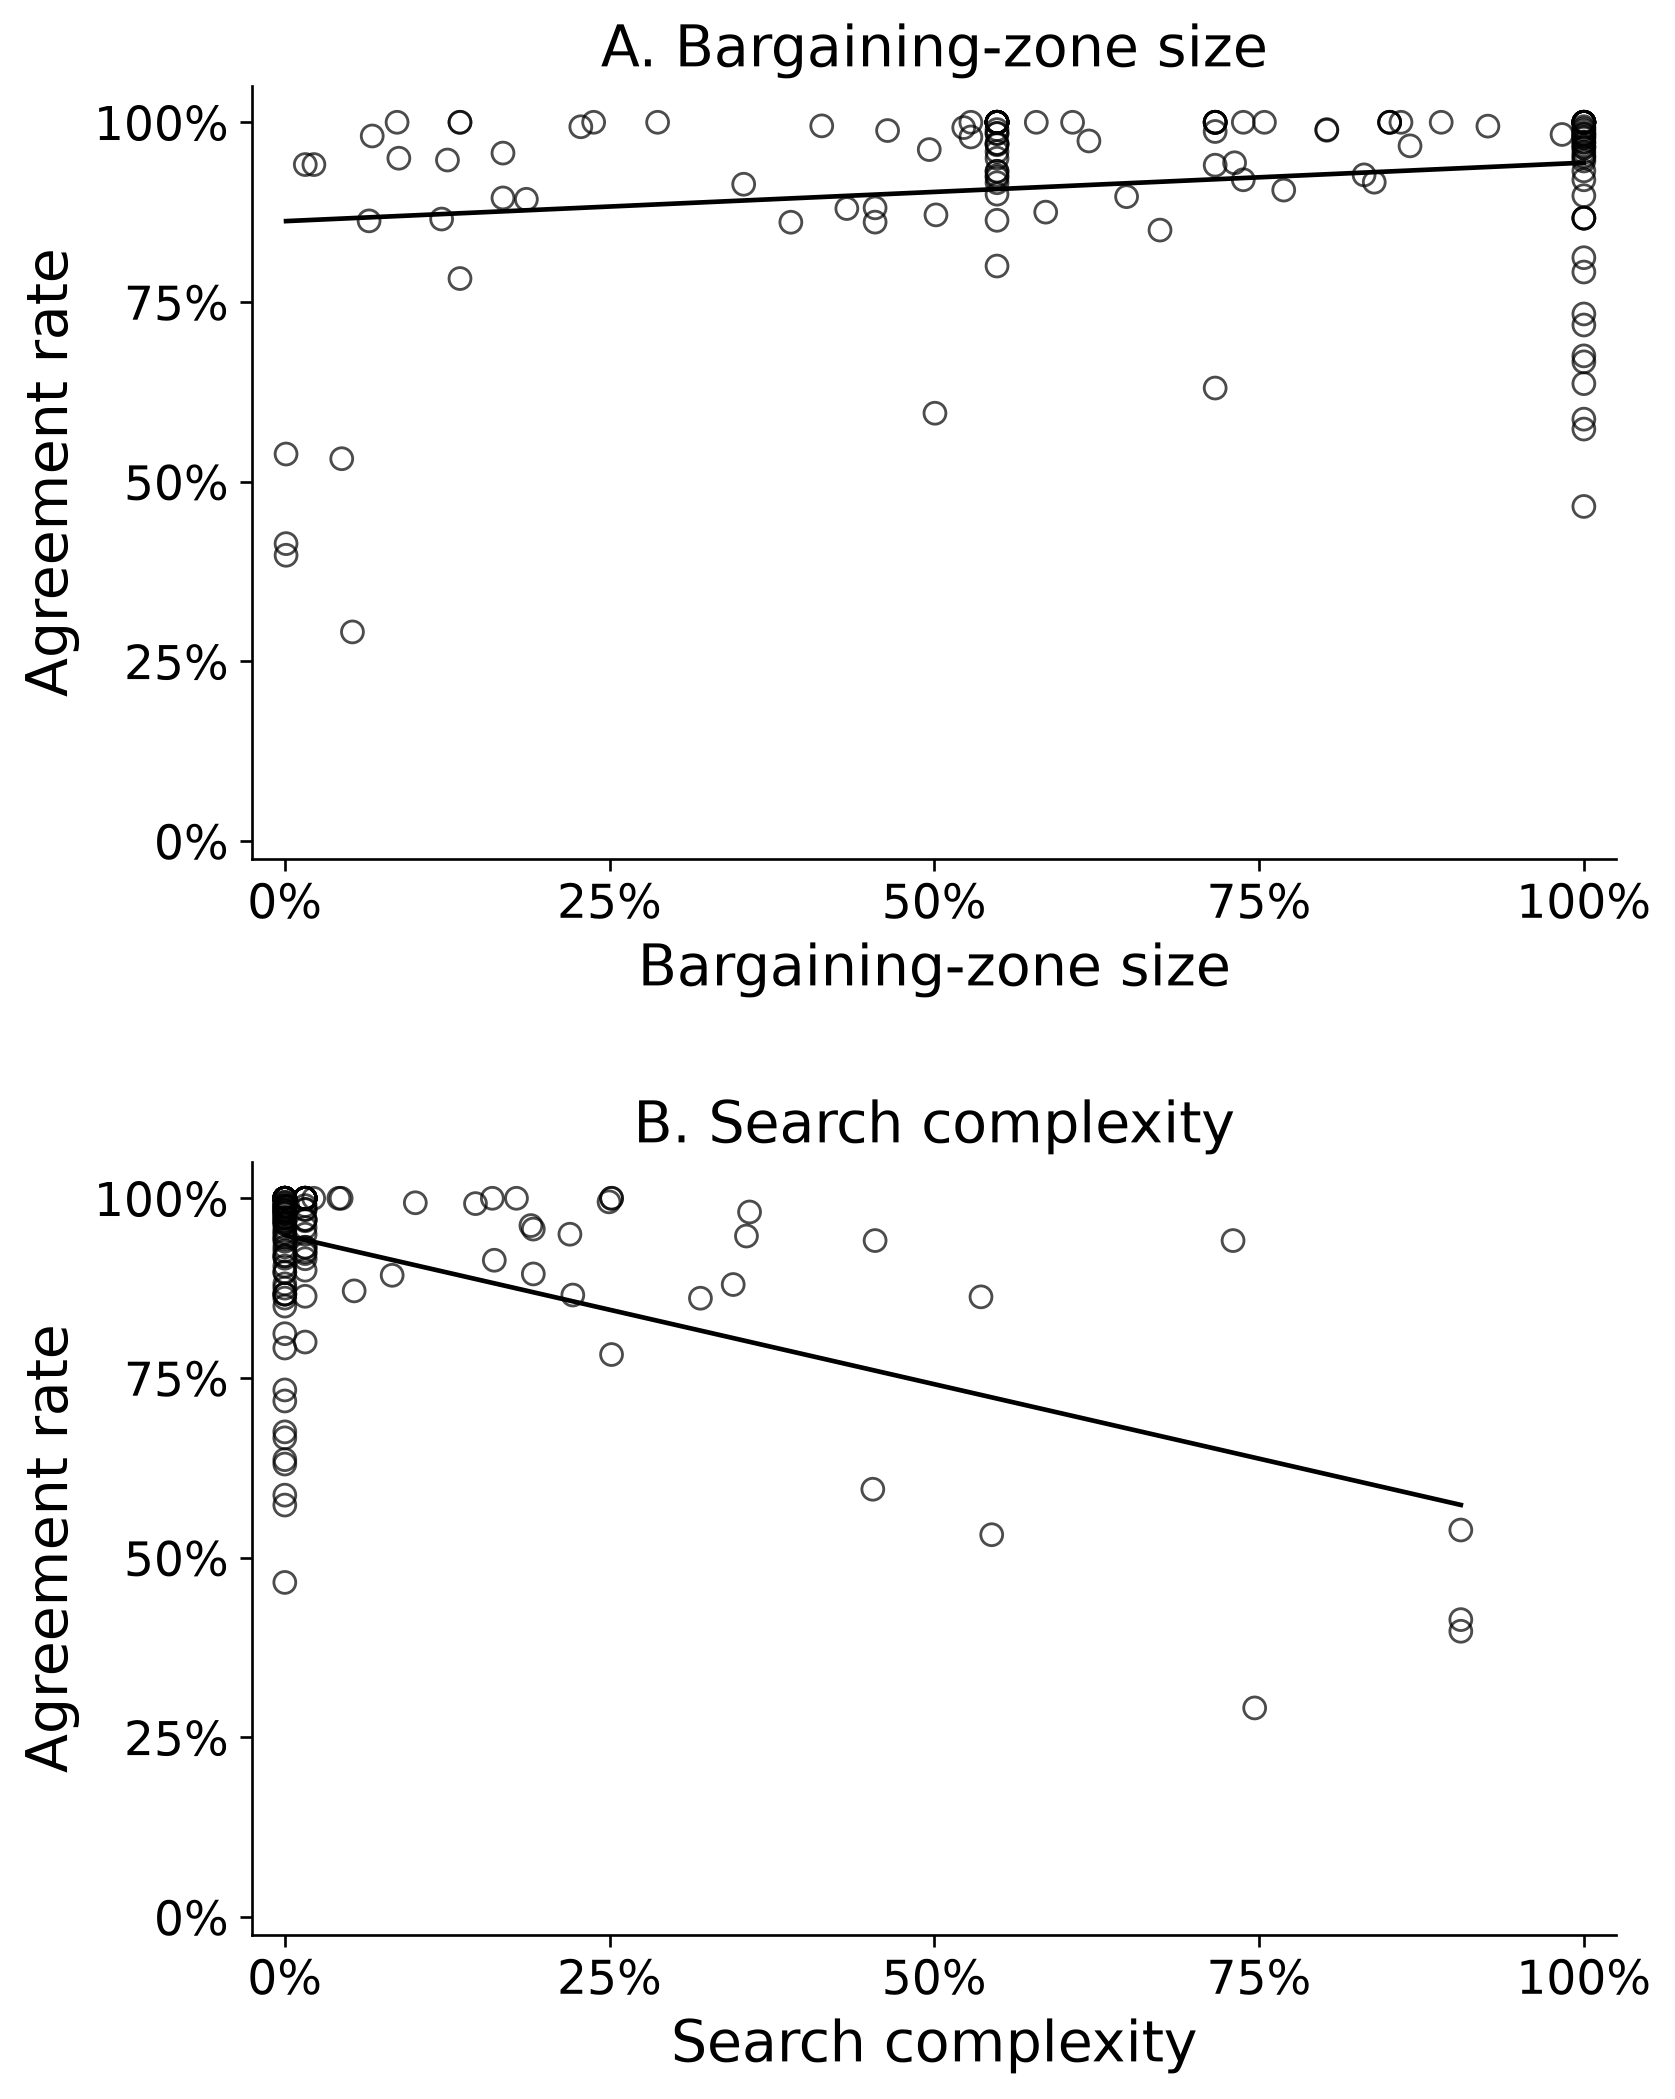

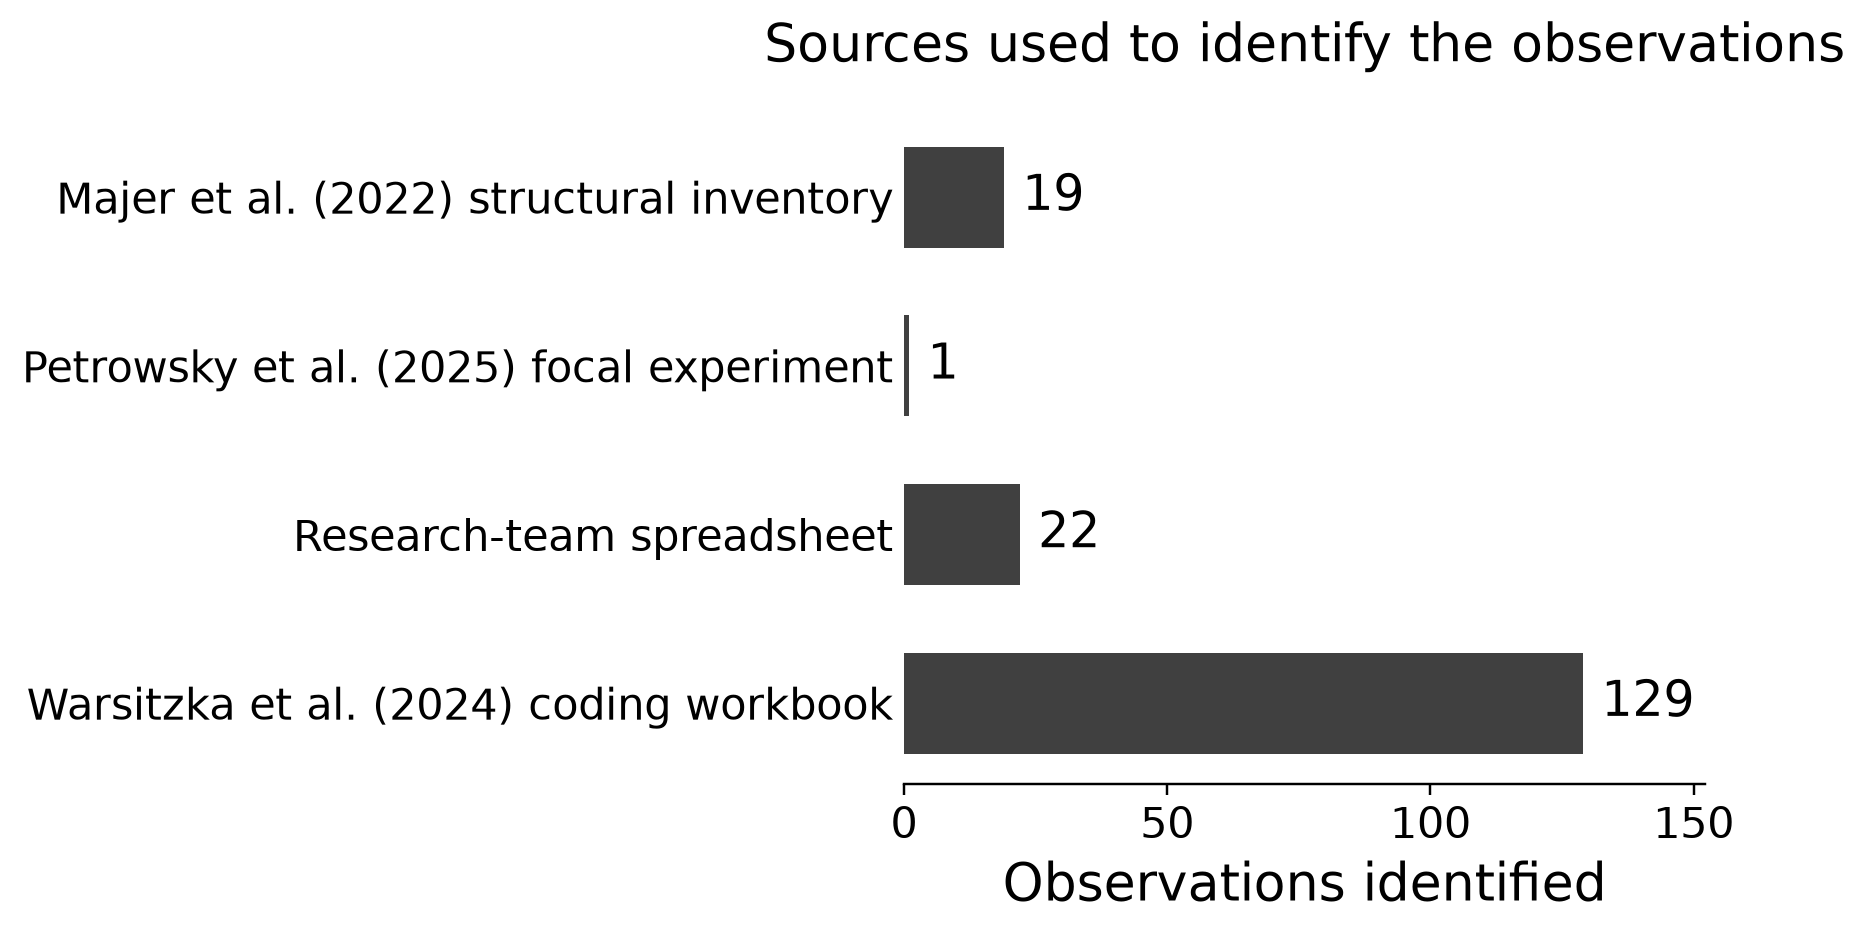

Saved results in outputs/.


In [4]:
for image in sorted((output / "figures").glob("*.png")):
    display(Image(filename=str(image)))
print("Saved results in outputs/.")


## 5. Original registration: main hypothesis tests

[`original_main_analysis.py`](original_main_analysis.py) applies the original four hypotheses to the same source-corrected data after combining independent experiment outcomes within each coded payoff record. Some records contain a documented combination of payoff versions. The five regression fits are the same ones shown in Table S2.

For this appendix, H1 concerns the bargaining-zone coefficient in Model 4; H2 concerns search complexity in Model 1; H3 compares the R-squared values of Models 2 and 5; and H4 concerns search complexity in Model 3. The original plan requires each primary test to pass, its 95% interval from 5,000 individual-row resamples to exclude zero in the predicted direction, and every single-row omission to retain support. The table reports each requirement separately before giving the combined decision. These checks select individual coded-payoff rows. No additional analyses from the original supplementary plan are run here.


In [5]:
display(pd.read_csv(output / "original_main_hypotheses.csv"))
display(pd.read_csv(output / "original_main_bootstrap.csv"))
print(json.loads((output / "original_main_summary.json").read_text(encoding="utf-8"))["confirmation"])


,hypothesis,prediction,model,term,n,primary_se,primary_p,primary_ci_low,primary_ci_high,primary_estimate,...,bootstrap_ci_high,bootstrap_draws_completed,bootstrap_criterion_met,omissions_passed,omissions_required,omission_criterion_met,omission_estimate_min,omission_estimate_max,largest_omission_p,full_confirmation_met
0,H1,Larger bargaining-zone size predicts a higher ...,M4,bargaining_zone_share,103,0.026126,3.152645e-03,0.027206,0.130858,0.079032,...,0.128450,5000,True,103,103,True,0.066038,0.082518,0.007884,True
1,H2,Greater search complexity predicts a lower agr...,M1,search_complexity,103,0.023548,1.046225e-07,-0.181632,-0.088205,-0.134919,...,-0.063832,5000,True,103,103,True,-0.140367,-0.114938,0.000006,True
2,H3,Search complexity and controls explain more va...,M2 minus M5,r_squared_difference,103,NaN,NaN,NaN,NaN,0.181331,...,0.336904,5000,True,103,103,True,0.115129,0.206581,NaN,True
3,H4,Search complexity predicts lower agreement rat...,M3,search_complexity,103,0.051498,4.652448e-03,-0.251516,-0.047044,-0.149280,...,-0.058216,5000,True,103,103,True,-0.185202,-0.111832,0.019164,True


,hypothesis,ci_low,ci_high,draws_requested,draws_completed,invalid_draws,seed,criterion_met
0,H1,0.027704,0.128450,5000,5000,0,20261113,True
1,H2,-0.192087,-0.063832,5000,5000,0,20261113,True
2,H3,0.024045,0.336904,5000,5000,0,20261113,True
3,H4,-0.249742,-0.058216,5000,5000,0,20261113,True


The primary test, bootstrap interval and every individual-row omission must all pass
